# Send와 동적 팬아웃

**이 노트북에서 할 일**

1. 문서 하나를 받아 글자 수를 세는 노드를 그래프 없이 먼저 불러 봅니다.
2. 문서 수만큼 `Send`를 만드는 조건 함수를 만들어 그 목록을 살펴봅니다.
3. 그 조건 함수를 붙인 그래프를 실행해 같은 노드가 몇 번 지나는지 봅니다.
4. 넣는 문서 수를 바꾸고 결과 칸의 규칙도 없애 두 가지를 견줍니다.

**준비물** — 이 절은 OpenAI API 키를 쓰지 않습니다.
모델 요청이 0번이라 드는 비용이 없습니다.
읽어 오는 자료 파일도 없고 새로 쓰는 파일도 없습니다.
실행 시간은 1분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangGraph 1.2.11을 설치합니다.
메시지 클래스를 쓰지 않아 04절보다 설치할 패키지가 하나 줄었습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
노드와 조건 함수를 그래프 없이 먼저 부른 뒤 그래프에 붙이는 자리입니다.
8절과 9절은 값을 하나씩 바꿔 보는 자리입니다.
10절은 세 실행을 기록 한 줄씩으로 만들어 표로 견주는 자리입니다.
준비부터 끝까지 함께 실행하고 실습 시간에 다시 읽습니다.

실습 폴더 `labs/part4/ch13-langgraph-basics`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

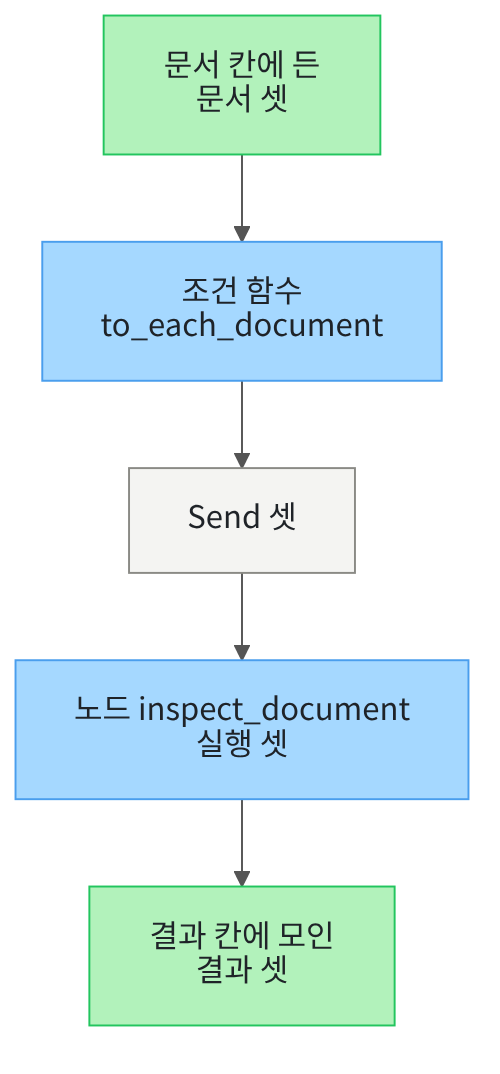

맨 위 초록 상자가 문서 칸에 넣은 문서 셋입니다.
그 아래 파란 상자가 우리가 만든 조건 함수입니다.
가운데 회색 상자가 라이브러리가 주는 `Send` 셋입니다.
그 아래 파란 상자가 같은 노드의 실행 셋입니다.
맨 아래 초록 상자가 결과가 모이는 칸입니다.

## 1. 준비

첫 셀은 패키지 하나를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11"
from importlib.metadata import version

print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.


langgraph: 1.2.11


**결과 읽기** — 설치가 끝나면 `langgraph: 1.2.11`이 보입니다.
이 노트북의 출력은 2026-09-19에 이 판으로 실행한 결과입니다.

다음 셀은 이름 일곱 개를 불러옵니다.
앞의 다섯은 02절에서 불러온 것과 같습니다.
뒤의 둘이 이 절에서 처음 쓰는 이름입니다.

In [2]:
# 02절 이름 다섯 개에 이 절 이름 두 개를 더해 불러옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langgraph.errors import InvalidUpdateError

print("이 절에서 처음 쓰는 이름:", "Send")

이 절에서 처음 쓰는 이름: Send


**결과 읽기** — 출력 줄 `이 절에서 처음 쓰는 이름: Send`가 보입니다.
객체 `Send`는 갈 노드 이름과 그 실행에만 넘길 상태를 함께 담습니다.
함께 불러온 `InvalidUpdateError`는 9절에서 오류를 받을 때 씁니다.

## 2. 이 절에서 쓸 값 정하기

01절부터 쓴 첫 질문을 글자까지 같게 씁니다.
그리고 이 절에서 나눠 보낼 짧은 안내 문서 세 건을 정합니다.
문서 하나는 번호 하나와 글 하나를 담은 딕셔너리입니다.

In [3]:
# 01절 질문과 이 절에서 나눠 보낼 안내 문서 세 건을 정합니다
first_question = "  대출 기간은 며칠인가요?  "
documents = [
    {"번호": "D01", "글": "대출은 한 번에 일곱 권까지 할 수 있습니다"},
    {"번호": "D02", "글": "대출 기간은 열나흘입니다"},
    {"번호": "D03", "글": "반납함은 출입구 옆에 있습니다"},
]
print("첫 질문:", first_question)
print("첫 질문의 글자 수:", len(first_question))
print("문서 수:", len(documents))

첫 질문:   대출 기간은 며칠인가요?  
첫 질문의 글자 수: 17
문서 수: 3


**결과 읽기** — 출력 줄 `첫 질문의 글자 수: 17`은 01절부터 이어지는 같은 값입니다.
출력 줄 `문서 수: 3`이 이 절에서 나눠 보낼 문서 수입니다.
문서 수는 뒤에서 한 건으로 줄여 다시 실행해 봅니다.

다음 셀은 문서 목록을 한 줄씩 펼쳐 봅니다.

In [4]:
# 문서 목록을 라벨 줄 아래에 한 줄씩 출력합니다
print("문서 칸에 넣을 문서 목록")
for document in documents:
    print(document["번호"], "|", document["글"])

문서 칸에 넣을 문서 목록
D01 | 대출은 한 번에 일곱 권까지 할 수 있습니다
D02 | 대출 기간은 열나흘입니다
D03 | 반납함은 출입구 옆에 있습니다


**결과 읽기** — 라벨 줄 `문서 칸에 넣을 문서 목록` 아래 세 줄이 나옵니다.
첫 줄은 `D01 |`로 시작하고 마지막 줄은 `D03 |`으로 시작합니다.
글의 길이는 문서마다 다릅니다.

## 3. 상태 형식과 출력 함수

이 절 상태에는 문서 칸과 결과 칸이 더 필요합니다.
결과 칸에는 갈래마다 결과 한 줄이 들어오므로 02절 규칙을 적습니다.
칸 구성이 04절과 달라 형식 이름도 새로 붙입니다.

In [5]:
# 02절 규칙을 쓴 문서 칸과 결과 칸을 둔 상태 형식을 만듭니다
class FanState(TypedDict):
    question: str
    documents: list[dict]
    results: Annotated[list[dict], operator.add]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
문서 칸에는 규칙을 적지 않았습니다. 넣은 값을 그대로 읽기만 하기 때문입니다.
결과 칸과 실행 흔적 칸에는 02절에서 쓴 같은 규칙을 적었습니다.
표시 `Annotated`의 둘째 자리에 적은 함수가 그 칸의 규칙입니다.

다음 셀은 01절부터 쓴 출력 함수를 이 절 칸에 맞춘 판입니다.

In [6]:
# 상태의 칸 네 개를 라벨 줄 아래에 한 줄씩 출력합니다
def print_state(label, state):
    print(label)
    print("질문 칸 |", state["question"])
    print("문서 칸의 문서 수 |", len(state["documents"]))
    print("결과 칸의 줄 수 |", len(state["results"]))
    print("실행 흔적 칸 |", state["trace"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
문서 칸과 결과 칸은 줄이 여러 개라 여기서는 개수만 적습니다.
04절 판과 견주면 메시지 칸 줄이 빠지고 문서 칸과 결과 칸 줄이 들어왔습니다.

## 4. 문서 하나를 보는 노드

먼저 01절부터 쓴 노드를 그대로 다시 정의합니다.
코드는 04절 판과 글자까지 같습니다.

In [7]:
# 질문 칸의 앞뒤 빈칸을 없애고 실행 흔적에는 자기 이름만 담아 냅니다
def normalize(state):
    clean = state["question"].strip()
    return {"question": clean, "trace": ["normalize"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `strip()`은 글 앞뒤의 빈칸을 없앱니다.
이 노드는 문서 칸과 결과 칸을 건드리지 않습니다.

다음 셀이 이 절의 새 노드입니다.
이 노드는 전체 상태가 아니라 문서 하나만 담은 상태를 받습니다.

In [8]:
# 문서 하나를 받아 글자 수를 세고 결과 한 줄만 담아 냅니다
def inspect_document(state):
    document = state["document"]
    row = {"번호": document["번호"]}
    row["글자 수"] = len(document["글"])
    row["자리"] = state["place"]
    return {"results": [row], "trace": ["inspect_document"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드는 결과 칸에 줄 하나만 담아 냅니다.
줄에는 문서 번호와 글자 수와 자리 번호를 적습니다.
자리 번호는 몇 번째 문서였는지 나중에 맞추려고 함께 담습니다.

다음 셀은 그래프 없이 이 노드를 직접 불러 봅니다.

In [9]:
# 그래프 없이 노드 하나에 문서 하나만 넣어 불러 봅니다
one_input = {"document": documents[0], "place": 0}
one_update = inspect_document(one_input)
print("노드가 낸 결과 한 줄:", one_update["results"][0])
print("노드가 낸 실행 흔적:", one_update["trace"])

노드가 낸 결과 한 줄: {'번호': 'D01', '글자 수': 24, '자리': 0}
노드가 낸 실행 흔적: ['inspect_document']


**결과 읽기** — 출력 줄 `노드가 낸 결과 한 줄: {'번호': 'D01', '글자 수': 24, '자리': 0}`이 보입니다.
칸 이름 `results`에 들어갈 줄 하나가 이런 모양입니다.
출력 줄 `노드가 낸 실행 흔적: ['inspect_document']`도 자기 이름 하나뿐입니다.
02절이 정한 약속을 이 노드도 지킵니다.

## 5. Send 목록을 만드는 조건 함수

03절 조건 함수는 이름표 하나를 내놓았습니다.
이 절 조건 함수는 `Send` 여러 개를 담은 목록을 내놓습니다.
목록의 길이가 곧 그 노드를 지나는 횟수입니다.
빈 목록을 만들고 `for`와 `append`로 하나씩 채웁니다.

In [10]:
# 문서 하나마다 Send 하나를 만들어 목록에 담아 냅니다
def to_each_document(state):
    sends = []
    place = 0
    for document in state["documents"]:
        sends.append(Send("inspect_document", {"document": document, "place": place}))
        place = place + 1
    return sends

**결과 읽기** — 정의 셀이라 출력이 없습니다.
객체 `Send`의 첫 자리에 갈 노드 이름을 적습니다.
둘째 자리에는 그 실행에만 넘길 상태를 딕셔너리로 적습니다.
변수 `place`는 몇 번째 문서인지 세는 번호이고 한 바퀴마다 하나씩 늘어납니다.

다음 셀은 그래프 없이 이 조건 함수만 불러 봅니다.

In [11]:
# 그래프 없이 조건 함수만 불러 만들어진 Send를 봅니다
made = to_each_document({"documents": documents})
print("만든 Send 수:", len(made))
print("첫 Send가 갈 노드 이름:", made[0].node)
print("첫 Send가 넘길 문서의 번호:", made[0].arg["document"]["번호"])
print("첫 Send가 넘길 자리 번호:", made[0].arg["place"])
print("셋째 Send가 넘길 문서의 번호:", made[2].arg["document"]["번호"])

만든 Send 수: 3
첫 Send가 갈 노드 이름: inspect_document
첫 Send가 넘길 문서의 번호: D01
첫 Send가 넘길 자리 번호: 0
셋째 Send가 넘길 문서의 번호: D03


**결과 읽기** — 출력 줄 `만든 Send 수: 3`이 문서 수와 같습니다.
출력 줄 `첫 Send가 갈 노드 이름: inspect_document`가 목적지입니다.
출력 줄 `첫 Send가 넘길 문서의 번호: D01`과 `첫 Send가 넘길 자리 번호: 0`이 그 실행 몫입니다.
출력 줄 `셋째 Send가 넘길 문서의 번호: D03`은 다른 문서를 가리킵니다.
세 `Send`는 목적지가 같고 넘길 상태만 서로 다릅니다.

## 6. 조립과 실행

설계 객체를 만들고 노드 두 개를 등록합니다.
같은 노드를 여러 번 지나도 등록은 한 번만 합니다.

In [12]:
# 설계 객체를 만들고 노드 두 개를 등록합니다
builder = StateGraph(FanState)
builder.add_node("normalize", normalize)
builder.add_node("inspect_document", inspect_document)
print("등록한 노드 수:", len(builder.nodes))

등록한 노드 수: 2


**결과 읽기** — 출력 줄 `등록한 노드 수: 2`가 보입니다.
01절·02절은 둘이었고 03절은 넷, 04절은 셋이었습니다.

다음 셀은 엣지를 적고 컴파일합니다.
03절은 `add_conditional_edges`의 셋째 자리에 이름표 표를 적었습니다.
이 절은 목적지가 `Send` 안에 들어 있어 그 자리를 적지 않습니다.

In [13]:
# 고정 엣지 두 개와 조건부 엣지 하나를 적고 컴파일합니다
builder.add_edge(START, "normalize")
builder.add_conditional_edges("normalize", to_each_document)
builder.add_edge("inspect_document", END)
graph = builder.compile()
print("고정 엣지로 적은 수:", len(builder.edges))
print("컴파일 결과의 종류:", type(graph))

고정 엣지로 적은 수: 2
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 2`가 보입니다.
조건부 엣지는 이 수에 들어가지 않습니다.
출력 줄의 종류 이름 `CompiledStateGraph`는 01절부터 같습니다.

다음 셀은 문서 세 건을 넣고 실행합니다.
실행 전에 예상해 봅니다.
문서가 셋이니 결과 칸에도 줄이 셋 모일 것입니다.

In [14]:
# 문서 세 건을 넣고 그래프를 실행합니다
start_state = {"question": first_question, "documents": documents}
start_state["results"] = []
start_state["trace"] = []
three_result = graph.invoke(start_state)
print_state("문서 셋을 넣은 실행", three_result)
assert len(three_result["results"]) == 3

문서 셋을 넣은 실행
질문 칸 | 대출 기간은 며칠인가요?
문서 칸의 문서 수 | 3
결과 칸의 줄 수 | 3
실행 흔적 칸 | ['normalize', 'inspect_document', 'inspect_document', 'inspect_document']


**결과 읽기** — 줄 `결과 칸의 줄 수 | 3`이 모인 줄 수입니다.
줄 `실행 흔적 칸 |` 뒤에 이름이 넷 남았고 그 가운데 셋이 `inspect_document`입니다.
같은 노드를 한 번만 등록했는데 한 실행에서 세 번 지났습니다.
줄 `질문 칸 | 대출 기간은 며칠인가요?`는 01절부터 같은 값입니다.

다음 셀은 결과 칸을 모인 차례 그대로 펼쳐 봅니다.

In [15]:
# 결과 칸에 모인 줄을 모인 차례 그대로 출력합니다
print("결과 칸에 모인 차례")
for row in three_result["results"]:
    print(row["자리"], "|", row["번호"], "|", row["글자 수"])

결과 칸에 모인 차례
0 | D01 | 24
1 | D02 | 13
2 | D03 | 16


**결과 읽기** — 라벨 줄 `결과 칸에 모인 차례` 아래 세 줄이 나옵니다.
이번 실행에서는 `0 | D01 | 24`·`1 | D02 | 13`·`2 | D03 | 16` 차례로 나왔습니다.
모인 차례는 이번 실행에서 본 것이고 라이브러리가 약속한 것이 아닙니다.
그래서 아래 7절에서 자리 번호로 차례를 맞춰 봅니다.

## 7. 입력 차례대로 맞추기

갈래가 여러 개면 어느 갈래가 먼저 끝나는지 우리가 정하지 않습니다.
그래서 결과에 자리 번호를 함께 담아 두었습니다.
자리 번호를 0부터 세면서 그 번호를 가진 줄을 찾아 다시 담습니다.

In [16]:
# 자리 번호를 보고 입력 차례대로 다시 담습니다
def order_rows(rows):
    ordered = []
    for place in range(len(rows)):
        for row in rows:
            if row["자리"] == place:
                ordered.append(row)
    return ordered

**결과 읽기** — 정의 셀이라 출력이 없습니다.
바깥 `for`가 자리 번호를 0부터 하나씩 셉니다.
안쪽 `for`가 그 번호를 가진 줄을 찾아 새 목록에 담습니다.
이렇게 하면 모인 차례가 달라져도 결과 차례는 같습니다.

다음 셀은 그 함수를 불러 결과를 다시 출력합니다.

In [17]:
# 입력 차례대로 맞춘 결과를 라벨 줄 아래에 출력합니다
ordered_rows = order_rows(three_result["results"])
print("입력 차례대로 맞춘 결과")
for row in ordered_rows:
    print(row["자리"], "|", row["번호"], "|", row["글자 수"])

입력 차례대로 맞춘 결과
0 | D01 | 24
1 | D02 | 13
2 | D03 | 16


**결과 읽기** — 라벨 줄 `입력 차례대로 맞춘 결과` 아래 세 줄이 나옵니다.
첫 줄은 `0 | D01 | 24`이고 마지막 줄은 `2 | D03 | 16`입니다.
자리 번호가 0부터 차례로 올라갑니다.
넣은 문서 차례와 읽는 차례가 같아졌습니다.

## 8. 값 바꿔 보기 ① 넣는 문서 수를 하나로

바꿀 값은 문서 목록 하나입니다.
그래프도 노드도 그대로 두고 문서를 한 건만 넣습니다.
실행 전에 예상해 봅니다.
객체 `Send`가 하나만 만들어지니 결과 줄도 하나일 것입니다.

In [18]:
# 문서 목록만 한 건으로 줄여 같은 그래프를 실행합니다
one_state = {"question": first_question, "documents": documents[:1]}
one_state["results"] = []
one_state["trace"] = []
one_result = graph.invoke(one_state)
print_state("문서 하나를 넣은 실행", one_result)
assert len(one_result["results"]) == 1

문서 하나를 넣은 실행
질문 칸 | 대출 기간은 며칠인가요?
문서 칸의 문서 수 | 1
결과 칸의 줄 수 | 1
실행 흔적 칸 | ['normalize', 'inspect_document']


**결과 읽기** — 줄 `문서 칸의 문서 수 | 1`이 줄인 뒤의 문서 수입니다.
줄 `결과 칸의 줄 수 | 1`로 결과도 하나만 남았습니다.
줄 `실행 흔적 칸 | ['normalize', 'inspect_document']`에 이름이 둘뿐입니다.
같은 그래프인데 지나간 횟수가 달라졌습니다.

다음 셀은 두 실행을 나란히 견줍니다.

In [19]:
# 두 실행의 결과 줄 수와 실행 흔적 길이를 견줍니다
print("문서 셋을 넣은 실행의 결과 줄 수:", len(three_result["results"]))
print("문서 하나를 넣은 실행의 결과 줄 수:", len(one_result["results"]))
print("문서 셋을 넣은 실행의 실행 흔적 길이:", len(three_result["trace"]))
print("문서 하나를 넣은 실행의 실행 흔적 길이:", len(one_result["trace"]))
print("등록한 노드 수는 그대로:", len(builder.nodes))

문서 셋을 넣은 실행의 결과 줄 수: 3
문서 하나를 넣은 실행의 결과 줄 수: 1
문서 셋을 넣은 실행의 실행 흔적 길이: 4
문서 하나를 넣은 실행의 실행 흔적 길이: 2
등록한 노드 수는 그대로: 2


**결과 읽기** — 출력 줄 `문서 셋을 넣은 실행의 결과 줄 수: 3`과 `문서 하나를 넣은 실행의 결과 줄 수: 1`이 갈린 자리입니다.
출력 줄 `문서 셋을 넣은 실행의 실행 흔적 길이: 4`와 `문서 하나를 넣은 실행의 실행 흔적 길이: 2`도 함께 갈렸습니다.
출력 줄 `등록한 노드 수는 그대로: 2`는 두 실행에서 같습니다.
등록한 노드 수는 그대로인데 지나간 횟수만 입력 수를 따라갔습니다.

## 9. 값 바꿔 보기 ② 결과 칸의 규칙을 없애면

바꿀 값은 결과 칸에 적은 규칙 하나입니다.
같은 노드와 같은 엣지로 판을 하나 더 만들되 결과 칸의 규칙만 뺍니다.
실행 전에 예상해 봅니다.
여러 갈래가 한꺼번에 같은 칸에 갱신을 내면 합칠 방법이 없습니다.

In [20]:
# 결과 칸에만 규칙을 적지 않은 상태 형식을 하나 더 만듭니다
class NoRuleState(TypedDict):
    question: str
    documents: list[dict]
    results: list[dict]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
결과 칸에만 표시 `Annotated`를 쓰지 않았습니다.
실행 흔적 칸에는 규칙을 그대로 두었습니다.
02절에서 본 대로 규칙이 없는 칸은 덮어쓰기가 됩니다.

다음 셀은 이 형식으로 판을 하나 더 만듭니다.

In [21]:
# 같은 노드와 같은 엣지로 규칙 없는 판을 하나 더 만듭니다
plain_builder = StateGraph(NoRuleState)
plain_builder.add_node("normalize", normalize)
plain_builder.add_node("inspect_document", inspect_document)
plain_builder.add_edge(START, "normalize")
plain_builder.add_conditional_edges("normalize", to_each_document)
plain_builder.add_edge("inspect_document", END)
plain_graph = plain_builder.compile()
print("규칙 없는 판의 노드 수:", len(plain_builder.nodes))

규칙 없는 판의 노드 수: 2


**결과 읽기** — 출력 줄 `규칙 없는 판의 노드 수: 2`가 앞 그래프와 같습니다.
노드도 엣지도 앞 그래프와 같은 것을 씁니다.
다른 것은 상태 형식 하나뿐입니다.

다음 셀은 이 판에 문서 하나만 넣어 봅니다.

In [22]:
# 규칙 없는 판에 문서 하나만 넣어 실행합니다
plain_one = {"question": first_question, "documents": documents[:1]}
plain_one["results"] = []
plain_one["trace"] = []
plain_one_result = plain_graph.invoke(plain_one)
print("결과 칸의 줄 수:", len(plain_one_result["results"]))

결과 칸의 줄 수: 1


**결과 읽기** — 출력 줄 `결과 칸의 줄 수: 1`로 끝까지 지났습니다.
갈래가 하나면 같은 칸에 갱신이 하나만 들어옵니다.
규칙이 없어도 덮어쓰기로 끝나므로 오류가 나지 않습니다.

다음 셀은 같은 판에 문서 셋을 넣습니다.
오류가 날 수 있으므로 오류 이름을 적어 받아 둡니다.

In [23]:
# 규칙 없는 판에 문서 셋을 넣어 실행하고 오류를 받아 출력합니다
plain_three = {"question": first_question, "documents": documents}
plain_three["results"] = []
plain_three["trace"] = []
try:
    plain_graph.invoke(plain_three)
except InvalidUpdateError as error:
    message = str(error)
    print("받은 오류 이름: InvalidUpdateError")
    print("오류 글의 첫 줄:", message.split("\n")[0])

받은 오류 이름: InvalidUpdateError
오류 글의 첫 줄: At key 'results': Can receive only one value per step. Use an Annotated key to handle multiple values.


**결과 읽기** — 출력 줄 `받은 오류 이름: InvalidUpdateError`가 받은 오류입니다.
출력 줄 `오류 글의 첫 줄:` 뒤에 한 단계에 값 하나만 받을 수 있다는 안내가 붙습니다.
같은 안내가 표시 `Annotated`를 쓴 칸을 쓰라고 알려 줍니다.
셀은 오류를 받아 끝까지 실행됐고 그래프 실행만 멈췄습니다.
갈래가 여럿인 칸에는 합칠 규칙이 있어야 한다는 뜻입니다.

## 10. 세 실행을 기록 한 줄씩으로

끝까지 지난 실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~12와 01~04절에서 쓴 기록 한 줄과 같은 모양입니다.

In [24]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, state):
    row = {"실행": run_name}
    row["넣은 문서 수"] = len(state["documents"])
    row["결과 줄 수"] = len(state["results"])
    row["실행 흔적 길이"] = len(state["trace"])
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
04절 판과 견주면 담는 칸이 문서 수와 결과 줄 수와 실행 흔적 길이로 바뀌었습니다.
이 절이 견주는 값이 그 셋이기 때문입니다.

다음 셀은 세 실행의 기록을 한 목록에 담습니다.
오류가 난 실행은 상태가 남지 않아 담지 않습니다.

In [25]:
# 끝까지 지난 세 실행의 기록을 한 목록에 담습니다
run_rows = []
run_rows.append(run_row("문서 셋 · 규칙 있는 판", three_result))
run_rows.append(run_row("문서 하나 · 규칙 있는 판", one_result))
run_rows.append(run_row("문서 하나 · 규칙 없는 판", plain_one_result))
print("담은 기록 줄 수:", len(run_rows))

담은 기록 줄 수: 3


**결과 읽기** — 출력 줄 `담은 기록 줄 수: 3`이 보입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [26]:
# 실행과 넣은 문서 수와 결과 줄 수와 실행 흔적 길이를 라벨 줄 아래에 출력합니다
print("실행 | 넣은 문서 수 | 결과 줄 수 | 실행 흔적 길이")
for row in run_rows:
    print(row["실행"], "|", row["넣은 문서 수"], "|", row["결과 줄 수"], "|", row["실행 흔적 길이"])

실행 | 넣은 문서 수 | 결과 줄 수 | 실행 흔적 길이
문서 셋 · 규칙 있는 판 | 3 | 3 | 4
문서 하나 · 규칙 있는 판 | 1 | 1 | 2
문서 하나 · 규칙 없는 판 | 1 | 1 | 2


**결과 읽기** — 라벨 줄 아래 세 줄이 나옵니다.
첫 줄 `문서 셋 · 규칙 있는 판 | 3 | 3 | 4`만 넣은 문서 수가 셋입니다.
둘째 줄과 셋째 줄은 넣은 문서 수가 하나라 세 값이 모두 같습니다.
줄 `문서 하나 · 규칙 없는 판 | 1 | 1 | 2`는 바로 위 줄과 값이 같습니다.
규칙이 있는 판과 없는 판의 차이는 문서가 하나일 때 드러나지 않았습니다.

## 정리

1. 조건 함수가 낸 `Send` 목록의 길이만큼 같은 노드가 한 실행에서 여러 번 지났습니다.
2. 등록한 노드 수는 둘 그대로였고 넣은 문서 수에 따라 결과 줄 수만 달라졌습니다.
3. 결과 칸의 규칙을 빼자 문서 셋에서 `InvalidUpdateError`를 받았습니다.

06절에서는 노드가 상태 갱신과 다음 목적지를 함께 내놓는 `Command`를 씁니다.
이 절까지 다음에 갈 노드는 엣지나 조건 함수가 정했습니다.